In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display, HTML

%config InlineBackend.figure_format = 'svg'
FS = 44100  # Fréquence d'échantillonnage standard haute qualité

NOTES_NOMS = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]

def midi_to_freq(midi_note):
    return 440.0 * (2.0 ** ((midi_note - 69) / 12.0))

def freq_to_note(freq_hz):
    if freq_hz <= 0:
        return "N/A"
    midi_exact = 69 + 12 * np.log2(freq_hz / 440.0)
    midi_round = int(round(midi_exact))
    cents = int(round((midi_exact - midi_round) * 100))
    nom = NOTES_NOMS[midi_round % 12]
    octave = (midi_round // 12) - 1
    cv_volts = (midi_exact - 24) / 12.0  # 0V = C1 (MIDI 24)
    signe = "+" if cents >= 0 else ""
    return f"{nom}{octave} (MIDI {midi_round}, {signe}{cents} cents, CV: {cv_volts:.2f}V)"

# --- OUTIL DE RECHERCHE RAPIDE ---
frequence_test = 130.81  # Changez cette valeur pour identifier n'importe quelle fréquence !
print(f"🔎 {frequence_test} Hz correspond à : {freq_to_note(frequence_test)}\n")

# --- TABLEAU COMPLET DES OCTAVES C1 à C6 ---
lignes = []
for octave in range(1, 7):
    row = {"Octave": f"Octave {octave} ({octave-1}V)"}
    for i, nom in enumerate(NOTES_NOMS):
        midi = (octave + 1) * 12 + i
        row[nom] = f"{midi_to_freq(midi):.1f}"
    lignes.append(row)

df_notes = pd.DataFrame(lignes).set_index("Octave")
display(HTML("<b>Table des fréquences en Hz (La4 = 440 Hz) :</b>"))
display(df_notes)


🔎 130.81 Hz correspond à : C3 (MIDI 48, +0 cents, CV: 2.00V)



,C,C#,D,D#,E,F,F#,G,G#,A,A#,B
Octave,,,,,,,,,,,,
Octave 1 (0V),32.7,34.6,36.7,38.9,41.2,43.7,46.2,49.0,51.9,55.0,58.3,61.7
Octave 2 (1V),65.4,69.3,73.4,77.8,82.4,87.3,92.5,98.0,103.8,110.0,116.5,123.5
Octave 3 (2V),130.8,138.6,146.8,155.6,164.8,174.6,185.0,196.0,207.7,220.0,233.1,246.9
Octave 4 (3V),261.6,277.2,293.7,311.1,329.6,349.2,370.0,392.0,415.3,440.0,466.2,493.9
Octave 5 (4V),523.3,554.4,587.3,622.3,659.3,698.5,740.0,784.0,830.6,880.0,932.3,987.8
Octave 6 (5V),1046.5,1108.7,1174.7,1244.5,1318.5,1396.9,1480.0,1568.0,1661.2,1760.0,1864.7,1975.5


In [9]:
# 1. CALCULS RYTHMIQUES (BPM -> Millisecondes & Fréquence LFO)
def calc_bpm(bpm):
    noire_ms = 60000.0 / bpm
    return {
        "BPM": bpm,
        "Mesure (4 temps)": f"{noire_ms * 4:.1f} ms ({1000/(noire_ms*4):.2f} Hz)",
        "Noire (1/4)": f"{noire_ms:.1f} ms ({1000/noire_ms:.2f} Hz)",
        "Croche (1/8)": f"{noire_ms / 2:.1f} ms ({2000/noire_ms:.2f} Hz)",
        "Double-croche (1/16 - Pas séquenceur)": f"{noire_ms / 4:.1f} ms ({4000/noire_ms:.2f} Hz)",
    }

print("⏱️ REPÈRES TEMPORELS :", calc_bpm(170))

# 2. FILTRE PASSE-BAS / PASSE-HAUT RC (fc = 1 / (2 * pi * R * C))
def calc_rc(r_ohms, c_farads):
    fc = 1.0 / (2.0 * np.pi * r_ohms * c_farads)
    tau_ms = r_ohms * c_farads * 1000.0
    print(f"🔌 Filtre RC (R={r_ohms}Ω, C={c_farads*1e9:.1f}nF) -> Coupure fc = {fc:.1f} Hz | Constante de temps τ = {tau_ms:.2f} ms")

calc_rc(1000, 100e-9)   # Exemple filtre PWM
calc_rc(10000, 100e-9)  # Exemple enveloppe Decay

# 3. CONVERSION DÉCIBELS (dB <-> Ratio de tension / amplitude)
def db_to_gain(db):
    return 10 ** (db / 20.0)

def gain_to_db(gain):
    return 20.0 * np.log10(gain)

print(f"🔊 -3 dB (point de coupure filtre) = {db_to_gain(-3):.2f}x la tension | -6 dB = {db_to_gain(-6):.2f}x | +12 dB = {db_to_gain(12):.2f}x")


⏱️ REPÈRES TEMPORELS : {'BPM': 170, 'Mesure (4 temps)': '1411.8 ms (0.71 Hz)', 'Noire (1/4)': '352.9 ms (2.83 Hz)', 'Croche (1/8)': '176.5 ms (5.67 Hz)', 'Double-croche (1/16 - Pas séquenceur)': '88.2 ms (11.33 Hz)'}
🔌 Filtre RC (R=1000Ω, C=100.0nF) -> Coupure fc = 1591.5 Hz | Constante de temps τ = 0.10 ms
🔌 Filtre RC (R=10000Ω, C=100.0nF) -> Coupure fc = 159.2 Hz | Constante de temps τ = 1.00 ms
🔊 -3 dB (point de coupure filtre) = 0.71x la tension | -6 dB = 0.50x | +12 dB = 3.98x


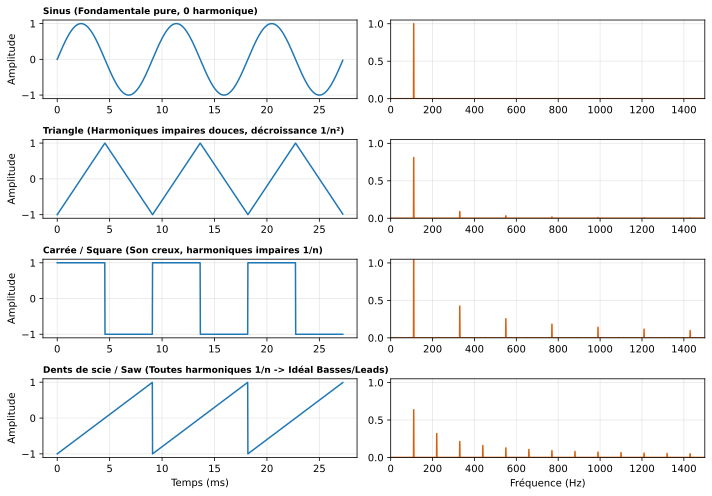

In [10]:
t = np.linspace(0, 1.0, FS, endpoint=False)
f_note = 110.0  # A2 (La2)

ondes = {
    "Sinus (Fondamentale pure, 0 harmonique)": np.sin(2 * np.pi * f_note * t),
    "Triangle (Harmoniques impaires douces, décroissance 1/n²)": signal.sawtooth(2 * np.pi * f_note * t, width=0.5),
    "Carrée / Square (Son creux, harmoniques impaires 1/n)": signal.square(2 * np.pi * f_note * t),
    "Dents de scie / Saw (Toutes harmoniques 1/n -> Idéal Basses/Leads)": signal.sawtooth(2 * np.pi * f_note * t),
}

fig, axes = plt.subplots(4, 2, figsize=(10, 7))
for idx, (titre, sig) in enumerate(ondes.items()):
    zoom = int((3 / f_note) * FS)
    axes[idx, 0].plot(t[:zoom] * 1000, sig[:zoom], color="#1f77b4")
    axes[idx, 0].set_title(titre, fontsize=9, loc="left", fontweight="bold")
    axes[idx, 0].set_ylabel("Amplitude")
    axes[idx, 0].grid(True, alpha=0.3)

    fft_vals = np.abs(np.fft.rfft(sig)) / len(sig) * 2
    fft_freqs = np.fft.rfftfreq(len(sig), 1 / FS)
    axes[idx, 1].plot(fft_freqs, fft_vals, color="#d95f0e")
    axes[idx, 1].set_xlim(0, 1500)
    axes[idx, 1].set_ylim(0, 1.05)
    axes[idx, 1].grid(True, alpha=0.3)

axes[-1, 0].set_xlabel("Temps (ms)")
axes[-1, 1].set_xlabel("Fréquence (Hz)")
plt.tight_layout()
plt.show()

for titre, sig in ondes.items():
    display(HTML(f"<b>{titre}</b>"))
    display(Audio(sig * 0.3, rate=FS))


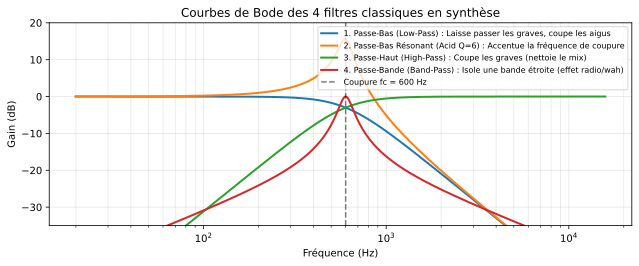

In [11]:
fc = 600.0  # Fréquence de coupure centrale (Hz)
w0 = 2 * np.pi * fc
Q_normal = 0.707
Q_acid = 6.0

filtres = {
    "1. Passe-Bas (Low-Pass) : Laisse passer les graves, coupe les aigus": ([w0**2], [1, w0/Q_normal, w0**2]),
    "2. Passe-Bas Résonant (Acid Q=6) : Accentue la fréquence de coupure": ([w0**2], [1, w0/Q_acid, w0**2]),
    "3. Passe-Haut (High-Pass) : Coupe les graves (nettoie le mix)": ([1, 0, 0], [1, w0/Q_normal, w0**2]),
    "4. Passe-Bande (Band-Pass) : Isole une bande étroite (effet radio/wah)": ([w0/Q_acid, 0], [1, w0/Q_acid, w0**2]),
}

w_freqs = np.logspace(1.3, 4.2, 600)
plt.figure(figsize=(9, 3.8))

for label, (b, a) in filtres.items():
    _, h = signal.freqs(b, a, worN=2 * np.pi * w_freqs)
    plt.semilogx(w_freqs, 20 * np.log10(np.maximum(np.abs(h), 1e-5)), linewidth=2, label=label)

plt.axvline(fc, color="black", linestyle="--", alpha=0.5, label=f"Coupure fc = {fc:.0f} Hz")
plt.title("Courbes de Bode des 4 filtres classiques en synthèse")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.ylim(-35, 20)
plt.grid(True, which="both", alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Écoute sur une onde en dents de scie à 82.41 Hz (E2)
saw_test = signal.sawtooth(2 * np.pi * 82.41 * np.linspace(0, 1.2, int(FS * 1.2), endpoint=False))
for label, (b, a) in filtres.items():
    bz, az = signal.bilinear(b, a, fs=FS)
    y = signal.lfilter(bz, az, saw_test)
    y = y / np.max(np.abs(y)) * 0.35
    display(HTML(f"<b>{label}</b>"))
    display(Audio(y, rate=FS))


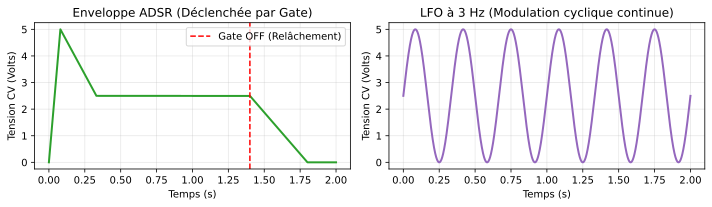

In [12]:
t_mod = np.linspace(0, 2.0, int(FS * 2.0), endpoint=False)

# 1. Construction d'une enveloppe ADSR (Attack, Decay, Sustain, Release)
A, D, S_level, R = 0.08, 0.25, 0.5, 0.4
note_off = 1.4  # Relâchement de la touche à 1.4s

env = np.zeros_like(t_mod)
for i, ti in enumerate(t_mod):
    if ti < A:
        env[i] = ti / A
    elif ti < A + D:
        env[i] = 1.0 - (1.0 - S_level) * ((ti - A) / D)
    elif ti < note_off:
        env[i] = S_level
    elif ti < note_off + R:
        env[i] = S_level * (1.0 - (ti - note_off) / R)

# 2. Construction d'un LFO (onde sinus lente à 3 Hz)
lfo = 0.5 * (1.0 + np.sin(2 * np.pi * 3.0 * t_mod))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.plot(t_mod, env * 5.0, color="#2ca02c", linewidth=2)
ax1.axvline(note_off, color="red", linestyle="--", label="Gate OFF (Relâchement)")
ax1.set_title("Enveloppe ADSR (Déclenchée par Gate)")
ax1.set_xlabel("Temps (s)")
ax1.set_ylabel("Tension CV (Volts)")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(t_mod, lfo * 5.0, color="#9467bd", linewidth=2)
ax2.set_title("LFO à 3 Hz (Modulation cyclique continue)")
ax2.set_xlabel("Temps (s)")
ax2.set_ylabel("Tension CV (Volts)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


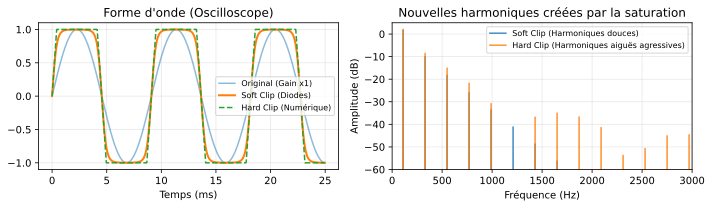

In [13]:
t_clip = np.linspace(0, 1.0, FS, endpoint=False)
sin_pur = np.sin(2 * np.pi * 110.0 * t_clip)

gain = 3.5
soft_clip = np.tanh(sin_pur * gain)               # Comportement diodes / transistor
hard_clip = np.clip(sin_pur * gain, -1.0, 1.0)    # Écrêtage numérique brutal

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))

# Forme d'onde temporelle
zoom = int(0.025 * FS)
ax1.plot(t_clip[:zoom]*1000, sin_pur[:zoom], label="Original (Gain x1)", alpha=0.5)
ax1.plot(t_clip[:zoom]*1000, soft_clip[:zoom], label="Soft Clip (Diodes)", linewidth=2)
ax1.plot(t_clip[:zoom]*1000, hard_clip[:zoom], label="Hard Clip (Numérique)", linestyle="--")
ax1.set_title("Forme d'onde (Oscilloscope)")
ax1.set_xlabel("Temps (ms)")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# Harmoniques générées par la distorsion
for sig, lbl in [(soft_clip, "Soft Clip (Harmoniques douces)"), (hard_clip, "Hard Clip (Harmoniques aiguës agressives)")]:
    fft_v = np.abs(np.fft.rfft(sig)) / len(sig) * 2
    fft_f = np.fft.rfftfreq(len(sig), 1 / FS)
    ax2.plot(fft_f, 20*np.log10(np.maximum(fft_v, 1e-5)), label=lbl, alpha=0.85)

ax2.set_xlim(0, 3000)
ax2.set_ylim(-60, 5)
ax2.set_title("Nouvelles harmoniques créées par la saturation")
ax2.set_xlabel("Fréquence (Hz)")
ax2.set_ylabel("Amplitude (dB)")
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

display(HTML("<b>1. Soft Clipping (Analogique / Diodes)</b>"))
display(Audio(soft_clip * 0.3, rate=FS))
display(HTML("<b>2. Hard Clipping (Numérique)</b>"))
display(Audio(hard_clip * 0.3, rate=FS))
